# DS605 – Lab 4: End-to-End Machine Learning – Airbnb Price Prediction
**Dataset:** Kaggle *New York City Airbnb Open Data* (`AB_NYC_2019.csv`) · **Target:** nightly `price` in USD

This notebook covers the full workflow requested in the assignment:

| Task | Contents |
|---|---|
| **1 – Data analysis & preparation** | data quality audit, missing values, outliers, EDA, feature engineering, feature selection |
| **2 – Model training & evaluation** | 4-model comparison, hyper-parameter tuning, test metrics, over/under-fitting checks, error analysis, saving the pipeline |
| **3 – Application** | the saved pipeline is served by `app.py` (Streamlit) – see the last sections |
| **4 – Final summary** | auto-generated results summary + limitations |

**How to run:** place `AB_NYC_2019.csv` in `data/`, install `requirements.txt`, start Jupyter **from the repository root** and choose *Kernel → Restart & Run All*.
Every plot is also written to `images/`, and the trained pipeline + metadata to `models/`.

In [ ]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import learning_curve, train_test_split

import airbnb_utils as U            # shared feature-engineering / modelling code

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

DATA_PATH = Path("data/AB_NYC_2019.csv")
MODELS_DIR, IMG_DIR, REPORTS_DIR = Path("models"), Path("images"), Path("reports")
for d in (MODELS_DIR, IMG_DIR, REPORTS_DIR):
    d.mkdir(exist_ok=True)

FAST = True                       # True -> fewer tuning iterations (quick test run)
CV, N_ITER = 3, (5 if FAST else 20)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Download AB_NYC_2019.csv from https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data "
        "and save it as data/AB_NYC_2019.csv (see README.md)")


def savefig(name):
    plt.tight_layout()
    plt.savefig(IMG_DIR / name, dpi=130, bbox_inches="tight")

---
# Task 1 – Data Analysis and Preparation
## 1.1 Load the data and inspect its structure

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.647,-73.972,Private room,149,1,9,2018-10-19,0.210,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.754,-73.984,Entire home/apt,225,1,45,2019-05-21,0.380,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.809,-73.942,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.685,-73.960,Entire home/apt,89,1,270,2019-07-05,4.640,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.799,-73.944,Entire home/apt,80,10,9,2018-11-19,0.100,1,0


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

## 1.2 Data-quality audit: missing values, duplicates, ranges

In [3]:
miss = raw.isna().sum().to_frame("missing")
miss["pct"] = miss["missing"] / len(raw) * 100
display(miss[miss["missing"] > 0])

print("Duplicate rows:", raw.duplicated().sum())
no_reviews = raw["number_of_reviews"] == 0
print("last_review missing exactly when number_of_reviews == 0 :", bool((raw["last_review"].isna() == no_reviews).all()))
print("reviews_per_month missing exactly when number_of_reviews == 0 :", bool((raw["reviews_per_month"].isna() == no_reviews).all()))

num_cols = ["price", "minimum_nights", "number_of_reviews", "reviews_per_month",
            "calculated_host_listings_count", "availability_365"]
display(raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T)

,missing,pct
name,16,0.033
host_name,21,0.043
last_review,10052,20.558
reviews_per_month,10052,20.558


Duplicate rows: 0
last_review missing exactly when number_of_reviews == 0 : True
reviews_per_month missing exactly when number_of_reviews == 0 : True


,count,mean,std,min,1%,25%,50%,75%,99%,max
price,"48,895.000",152.721,240.154,0.000,30.000,69.000,106.000,175.000,799.000,"10,000.000"
minimum_nights,"48,895.000",7.030,20.511,1.000,1.000,1.000,3.000,5.000,45.000,"1,250.000"
number_of_reviews,"48,895.000",23.274,44.551,0.000,0.000,1.000,5.000,24.000,214.000,629.000
reviews_per_month,"38,843.000",1.373,1.680,0.010,0.020,0.190,0.720,2.020,7.196,58.500
calculated_host_listings_count,"48,895.000",7.144,32.953,1.000,1.000,1.000,1.000,2.000,232.000,327.000
availability_365,"48,895.000",112.781,131.622,0.000,0.000,0.000,45.000,227.000,365.000,365.000


**Missing-value decisions** (the checks above verify the pattern on the data you loaded)

| Column | Issue | Decision |
|---|---|---|
| `reviews_per_month`, `last_review` | missing together, exactly for listings with **zero reviews** – the value is *structurally* missing, not random | `reviews_per_month` → **0**; add flag `has_reviews`; **`last_review` is dropped** (a brand-new host cannot supply it, and it adds no information beyond `has_reviews`) |
| `name` | a handful of missing titles | → empty string (title features then become 0) |
| `host_name` | a handful missing | column dropped (identifier, not a price driver) |
| `id`, `host_id`, `host_name` | identifiers | dropped – they would only let a model memorise listings |

Imputing the zero-review case with the *median* would be wrong: it would invent reviews that do not exist.

## 1.3 The target variable and outlier handling

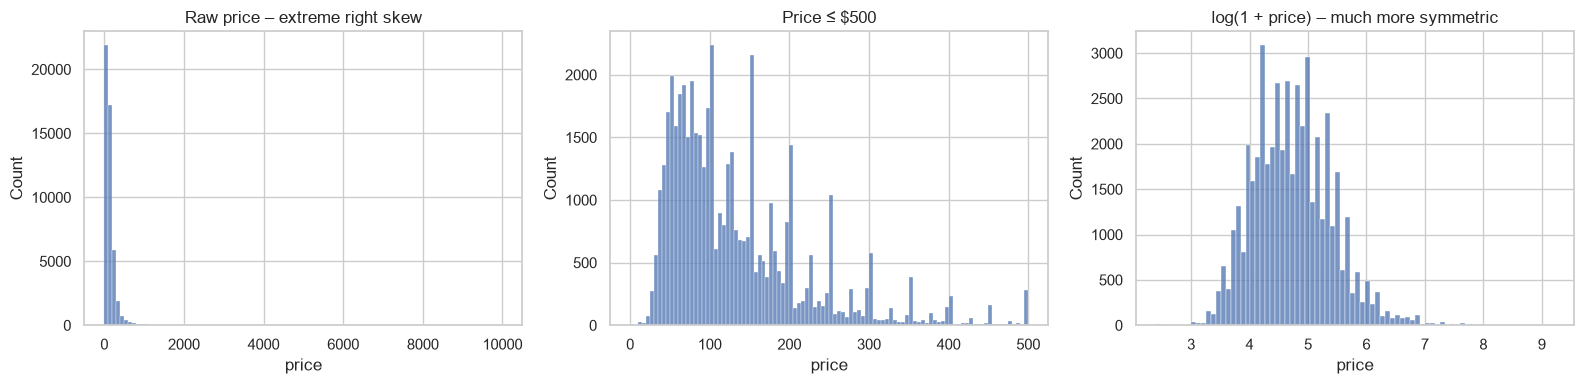

count   48,895.000
mean       152.721
std        240.154
min          0.000
50%        106.000
90%        269.000
99%        799.000
99.5%    1,000.000
99.9%    3,000.000
max     10,000.000
Name: price, dtype: float64

Listings with price == 0: 11


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw["price"], bins=100, ax=ax[0]); ax[0].set_title("Raw price – extreme right skew")
sns.histplot(raw.loc[raw["price"] <= 500, "price"], bins=100, ax=ax[1]); ax[1].set_title("Price ≤ $500")
sns.histplot(np.log1p(raw.loc[raw["price"] > 0, "price"]), bins=80, ax=ax[2]); ax[2].set_title("log(1 + price) – much more symmetric")
savefig("01_price_distribution.png"); plt.show()

print(raw["price"].describe(percentiles=[.5, .9, .99, .995, .999]))
print("\nListings with price == 0:", int((raw["price"] == 0).sum()))

**Observations & decisions**

* Price is heavily right-skewed with a few absurd values (placeholders at **$0** and listings costing thousands per night). A squared-error model would be dominated by these points.
* **Target transform:** the models are trained on `log1p(price)` (via `TransformedTargetRegressor`), so they learn *relative* rather than absolute errors, and predictions are converted back to dollars automatically.
* **Outlier rule:** drop listings priced below **$10** (includes the $0 placeholders) or above the **99.5th percentile**. This removes data-entry errors/ultra-luxury listings while keeping >99 % of rows. *Trade-off:* the final model is only reliable inside this price range (documented as a limitation).
* **Other numeric outliers** are handled *inside the pipeline* instead of deleting rows: `minimum_nights` is clipped to [1, 365] and heavy-tailed counts are `log1p`-transformed.

,value
rows_raw,"48,895.000"
duplicates_dropped,0.000
price_zero_or_below,11.000
price_below_min,11.000
price_above_cap,239.000
min_price,10.000
price_cap,"1,000.000"
upper_quantile,0.995
rows_clean,"48,645.000"


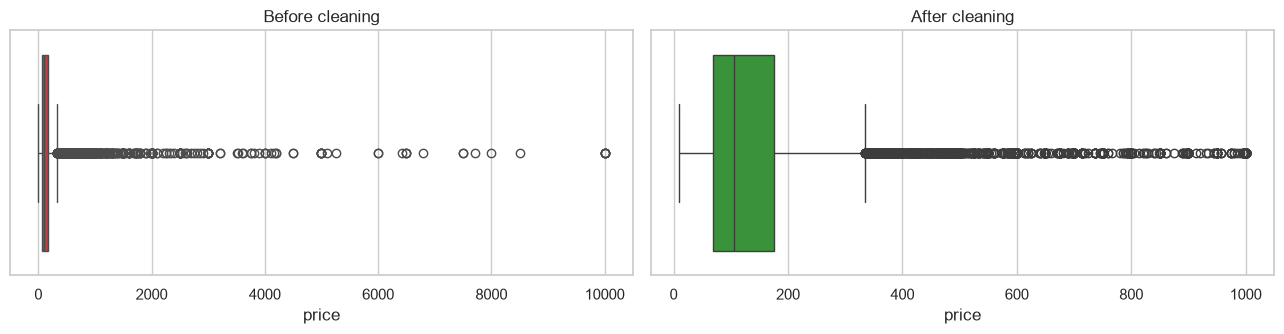

minimum_nights > 365 : 14 rows (clipped at 365 inside the pipeline)
availability_365 == 0: 35.9% of listings (flag `avail_zero`)


In [5]:
df, info = U.load_and_clean(DATA_PATH)
display(pd.Series(info).to_frame("value"))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
sns.boxplot(x=raw["price"], ax=ax[0], color="tab:red"); ax[0].set_title("Before cleaning")
sns.boxplot(x=df["price"], ax=ax[1], color="tab:green"); ax[1].set_title("After cleaning")
savefig("02_price_before_after_cleaning.png"); plt.show()

print("minimum_nights > 365 :", int((df["minimum_nights"] > 365).sum()), "rows (clipped at 365 inside the pipeline)")
print("availability_365 == 0:", f"{(df['availability_365'] == 0).mean():.1%}", "of listings (flag `avail_zero`)")

## 1.4 Exploratory data analysis – what drives price?

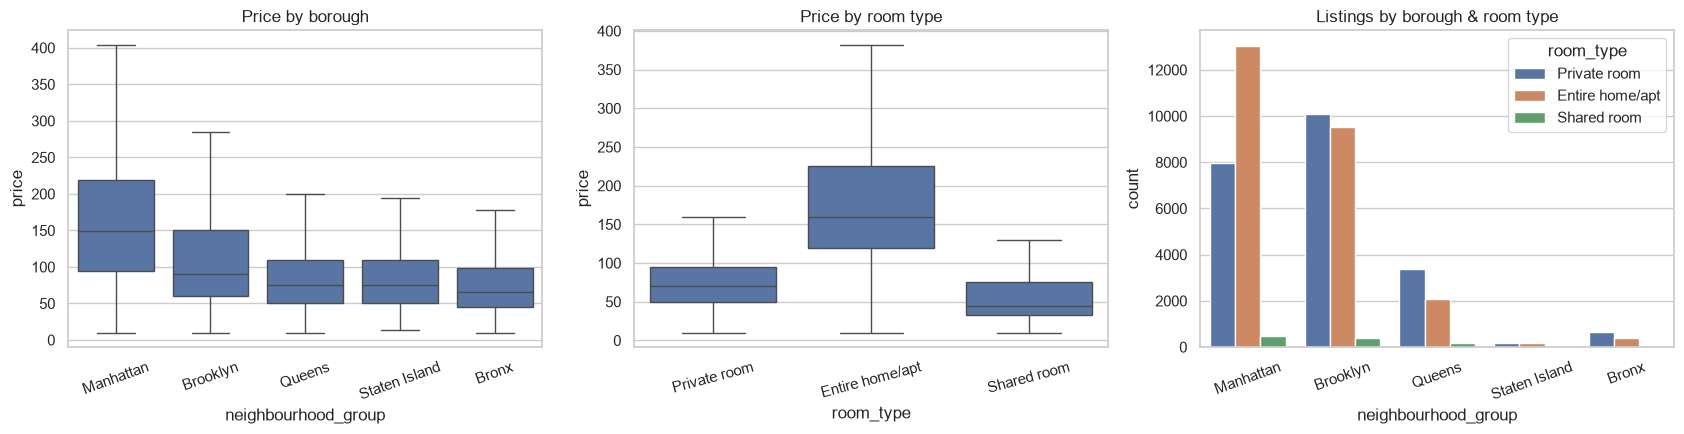

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.000,53.500,40.000
Brooklyn,145.000,65.000,36.000
Manhattan,190.000,90.000,69.000
Queens,120.000,60.000,37.000
Staten Island,100.000,50.000,30.000


In [6]:
df["log_price"] = np.log1p(df["price"])
order = df.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="neighbourhood_group", y="price", order=order, ax=ax[0], showfliers=False)
ax[0].set_title("Price by borough"); ax[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=df, x="room_type", y="price", ax=ax[1], showfliers=False)
ax[1].set_title("Price by room type"); ax[1].tick_params(axis="x", rotation=15)
sns.countplot(data=df, x="neighbourhood_group", order=order, hue="room_type", ax=ax[2])
ax[2].set_title("Listings by borough & room type"); ax[2].tick_params(axis="x", rotation=20)
savefig("03_price_by_borough_roomtype.png"); plt.show()

display(df.pivot_table(index="neighbourhood_group", columns="room_type", values="price", aggfunc="median"))

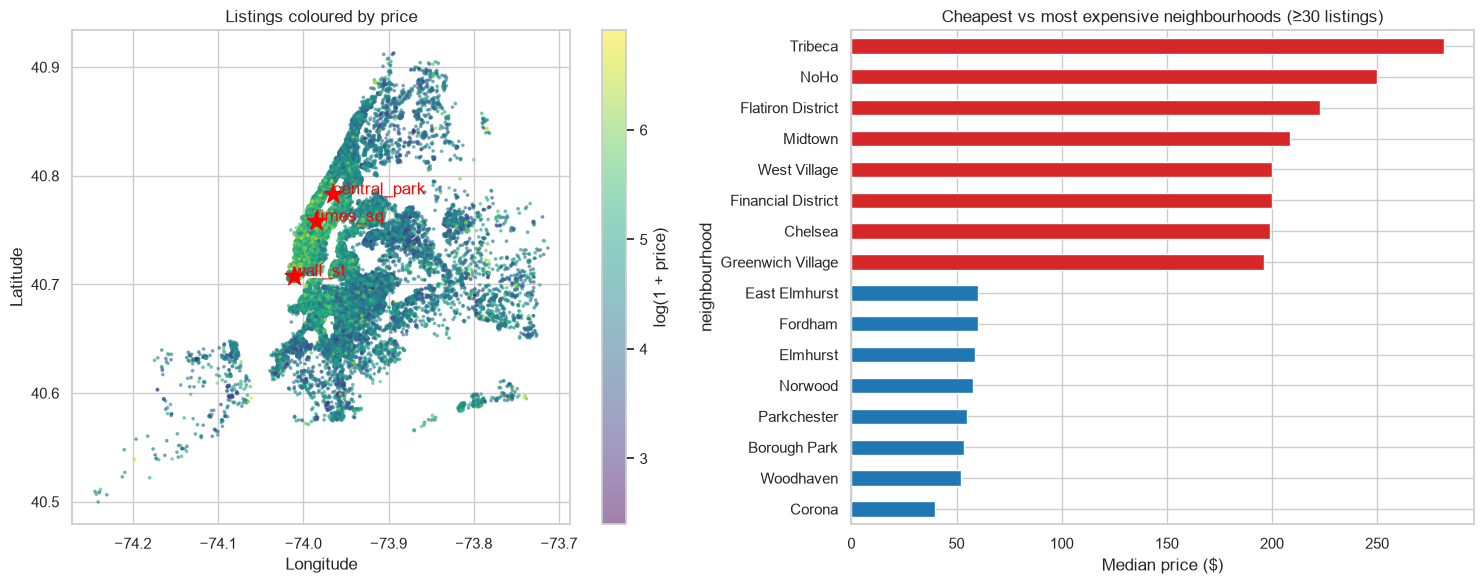

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sc = ax[0].scatter(df["longitude"], df["latitude"], c=df["log_price"], s=3, cmap="viridis", alpha=.5)
plt.colorbar(sc, ax=ax[0], label="log(1 + price)")
ax[0].set(xlabel="Longitude", ylabel="Latitude", title="Listings coloured by price")
lm = U.LANDMARKS
for k, (la, lo) in lm.items():
    ax[0].scatter(lo, la, marker="*", s=200, c="red"); ax[0].annotate(k, (lo, la), color="red")

nb = (df.groupby("neighbourhood")["price"].agg(["median", "size"]).query("size >= 30")
        .sort_values("median"))
top = pd.concat([nb.head(8), nb.tail(8)])
top["median"].plot.barh(ax=ax[1], color=["tab:blue"] * 8 + ["tab:red"] * 8)
ax[1].set(title="Cheapest vs most expensive neighbourhoods (≥30 listings)", xlabel="Median price ($)")
savefig("04_geography_and_neighbourhoods.png"); plt.show()

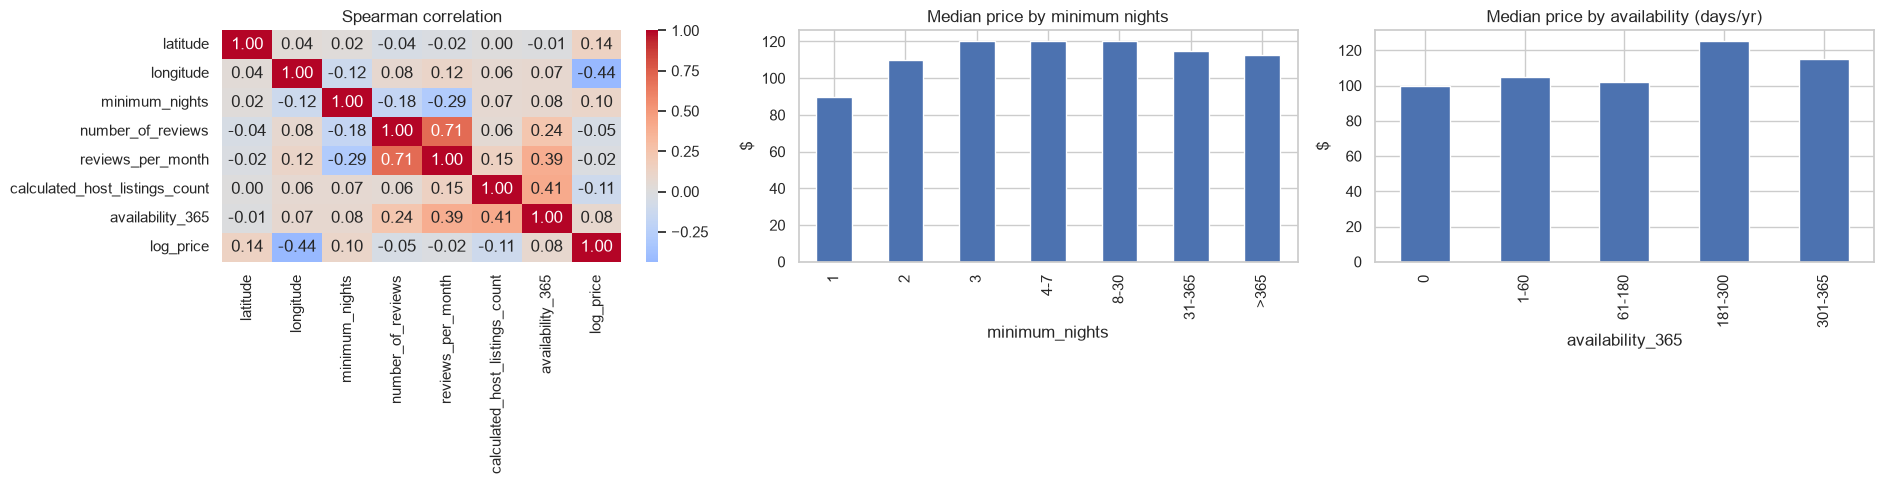

In [8]:
num_for_corr = ["latitude", "longitude", "minimum_nights", "number_of_reviews", "reviews_per_month",
                "calculated_host_listings_count", "availability_365"]
corr = df[num_for_corr].assign(log_price=df["log_price"]).corr(method="spearman")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("Spearman correlation")
bins = pd.cut(df["minimum_nights"], [0, 1, 2, 3, 7, 30, 365, np.inf], labels=["1", "2", "3", "4-7", "8-30", "31-365", ">365"])
df.groupby(bins, observed=True)["price"].median().plot.bar(ax=ax[1]); ax[1].set(title="Median price by minimum nights", ylabel="$")
ab = pd.cut(df["availability_365"], [-1, 0, 60, 180, 300, 365], labels=["0", "1-60", "61-180", "181-300", "301-365"])
df.groupby(ab, observed=True)["price"].median().plot.bar(ax=ax[2]); ax[2].set(title="Median price by availability (days/yr)", ylabel="$")
savefig("05_numeric_relationships.png"); plt.show()

In [9]:
# ---- Auto-generated summary of the key patterns found in THIS run -------------
b = df.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)
r = df.groupby("room_type")["price"].median().sort_values(ascending=False)
cor = corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False)
print("KEY DATA PATTERNS")
print(f"- Borough medians: " + ", ".join(f"{k} ${v:.0f}" for k, v in b.items()))
print(f"- Room-type medians: " + ", ".join(f"{k} ${v:.0f}" for k, v in r.items()))
print(f"- Strongest numeric correlates of log-price (Spearman): " + ", ".join(f"{k} ({v:+.2f})" for k, v in cor.head(3).items()))
print(f"- Share of listings that are entire homes: {(df['room_type'] == 'Entire home/apt').mean():.0%}; "
      f"with zero reviews: {(df['number_of_reviews'] == 0).mean():.0%}; "
      f"with 0 availability: {(df['availability_365'] == 0).mean():.0%}")
print(f"- Most expensive neighbourhood (>=30 listings): {nb.index[-1]} (${nb['median'].iloc[-1]:.0f}); "
      f"cheapest: {nb.index[0]} (${nb['median'].iloc[0]:.0f})")

KEY DATA PATTERNS
- Borough medians: Manhattan $149, Brooklyn $90, Queens $75, Staten Island $75, Bronx $65
- Room-type medians: Entire home/apt $160, Private room $70, Shared room $45
- Strongest numeric correlates of log-price (Spearman): longitude (-0.44), latitude (+0.14), calculated_host_listings_count (-0.11)
- Share of listings that are entire homes: 52%; with zero reviews: 20%; with 0 availability: 36%
- Most expensive neighbourhood (>=30 listings): Tribeca ($282); cheapest: Corona ($40)


**Interpretation guide.** Location (borough → neighbourhood → distance to Midtown/Downtown) and **room type** are expected to be the dominant drivers of price; the numeric columns (reviews, host listings, availability, minimum nights) have weak but non-zero monotonic relationships. The summary printed above is generated from your data, so it always matches the plots.

## 1.5 Feature engineering
All feature engineering lives in `airbnb_utils.add_features` and is the **first step of the saved pipeline**, so new listings entered in the app are transformed identically.

| Feature(s) | Why |
|---|---|
| `dist_times_sq_km`, `dist_wall_st_km`, `dist_central_park_km` | Haversine distance to the main demand centres turns raw lat/lon into a smooth "centrality" signal that trees and linear models can both use |
| `log_min_nights` (clipped to 365), `log_reviews`, `log_host_listings` | tame heavy right tails |
| `has_reviews`, `host_multi`, `avail_zero` | flags for structural states: never reviewed, professional multi-listing host, currently blocked/inactive listing |
| `name_len`, `name_words`, `has_premium_word`, `has_budget_word` | cheap text signals from the listing title (e.g. *luxury, loft, view* vs *cozy, shared, bunk*) |
| `neighbourhood_group`, `neighbourhood`, `room_type` | one-hot encoded; categories with <20 listings are grouped as "infrequent", and unseen neighbourhoods at prediction time are handled gracefully |

In [10]:
X, y = df[U.RAW_FEATURES], df[U.TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=U.RANDOM_STATE)
print(f"Train: {X_train.shape}  Test: {X_test.shape}   (the test set is NOT touched until the final evaluation)")

feat_preview = U.add_features(X_train.head())
display(feat_preview.T)

Train: (38916, 11)  Test: (9729, 11)   (the test set is NOT touched until the final evaluation)


,32520,34336,32715,43362,14761
neighbourhood_group,Brooklyn,Manhattan,Queens,Manhattan,Manhattan
neighbourhood,East Flatbush,Chelsea,Jamaica,East Village,East Village
room_type,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt
latitude,40.652,40.743,40.707,40.722,40.729
longitude,-73.948,-73.995,-73.783,-73.977,-73.983
dist_times_sq_km,12.156,1.858,17.942,4.029,3.184
dist_wall_st_km,8.105,4.184,19.208,3.343,3.396
dist_central_park_km,14.584,5.098,17.493,6.801,6.137
log_min_nights,1.386,3.401,1.099,3.296,1.609
log_reviews,0.693,1.386,3.555,0.000,1.792


## 1.6 Feature selection
1. **Removed up-front:** identifiers (`id`, `host_id`, `host_name`) and `last_review` (see 1.2).
2. **Mutual information** (non-linear, model-agnostic) between each engineered numeric feature and `log(1+price)`, computed on the **training split only** (no leakage). Features below 0.001 nats carry essentially no signal and are dropped.
3. Tree models additionally perform embedded selection, and Ridge shrinks weak coefficients.

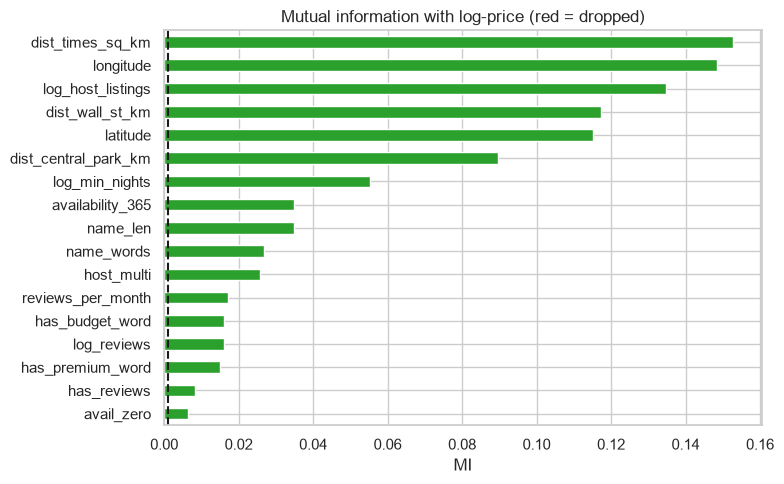

Kept 17 of 17 numeric features. Dropped: none


In [11]:
selected, mi = U.select_features_by_mi(X_train, np.log1p(y_train))
dropped = [f for f in U.NUM_FEATURES if f not in selected]

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:green" if f in selected else "tab:red" for f in mi.index]
mi[::-1].plot.barh(ax=ax, color=colors[::-1])
ax.axvline(0.001, ls="--", c="k"); ax.set(title="Mutual information with log-price (red = dropped)", xlabel="MI")
savefig("06_feature_selection_mi.png"); plt.show()
print(f"Kept {len(selected)} of {len(U.NUM_FEATURES)} numeric features. Dropped: {dropped or 'none'}")

---
# Task 2 – Model Training and Evaluation
## 2.1 Compare candidate regression models
Four models of increasing flexibility are trained with the **identical** preprocessing, on `log1p(price)`, with 3-fold cross-validation on the **training set**:

* **Linear Regression** – interpretable baseline
* **Ridge** – L2-regularised linear model (handles the many correlated one-hot columns)
* **Random Forest** – bagged trees, captures interactions and non-linearity
* **Hist Gradient Boosting** – boosted trees with early stopping, usually the strongest on tabular data

Selection metric: **RMSLE** (RMSE of log price ≈ relative error). MAE and R² in dollars are also reported, and the **train vs CV gap** is a first over-fitting check.

,model,cv_rmsle,train_rmsle,cv_mae,train_mae,cv_r2,train_r2,fit_time_s,overfit_gap_rmsle
0,Hist Gradient Boosting,0.399,0.359,45.395,41.399,0.439,0.520,9.471,0.040
1,Random Forest,0.401,0.329,45.442,37.772,0.424,0.550,1.576,0.072
2,Ridge,0.422,0.419,48.193,47.991,0.369,0.372,0.534,0.002
3,Linear Regression,0.422,0.419,48.198,47.987,0.369,0.372,0.967,0.002


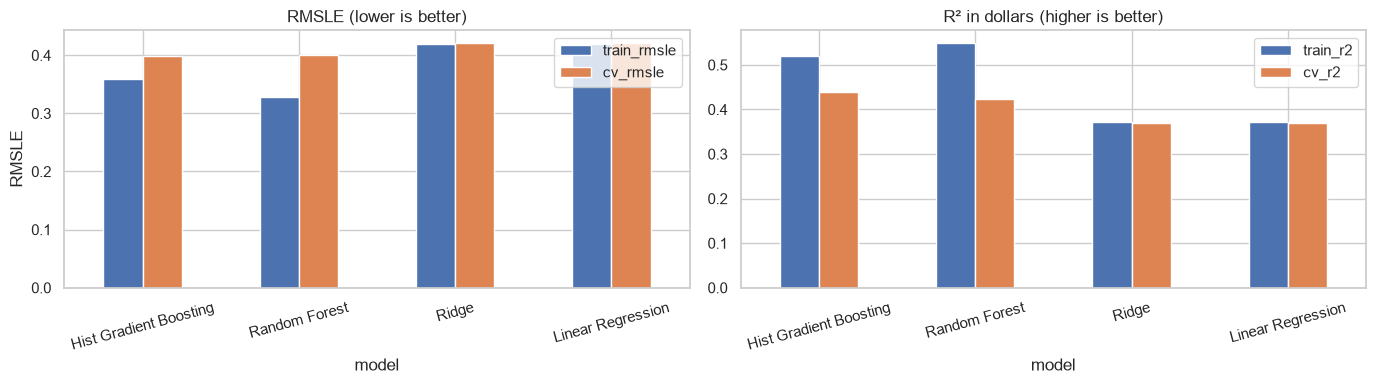

In [12]:
comparison = U.compare_models(X_train, y_train, selected, cv=CV)
display(comparison)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
comparison.set_index("model")[["train_rmsle", "cv_rmsle"]].plot.bar(ax=ax[0]); ax[0].set(title="RMSLE (lower is better)", ylabel="RMSLE"); ax[0].tick_params(axis="x", rotation=15)
comparison.set_index("model")[["train_r2", "cv_r2"]].plot.bar(ax=ax[1]); ax[1].set(title="R² in dollars (higher is better)"); ax[1].tick_params(axis="x", rotation=15)
savefig("07_model_comparison.png"); plt.show()

## 2.2 Hyper-parameter tuning
The best model family (lowest cross-validated RMSLE) is tuned with **randomised search** (3-fold CV, scoring = RMSLE). The search spaces include regularisation controls (`min_samples_leaf`, `l2_regularization`, `max_depth`, `alpha`…), so tuning also fights over-fitting.

In [13]:
best_name = comparison.iloc[0]["model"]
baseline_cv = comparison.iloc[0]["cv_rmsle"]
print(f"Best model family from comparison: {best_name} (CV RMSLE = {baseline_cv:.4f})")

if U.get_param_space(best_name):
    search = U.tune_model(best_name, X_train, y_train, selected, n_iter=N_ITER, cv=CV)
    model = search.best_estimator_
    best_params = {k.replace("regressor__model__", ""): v for k, v in search.best_params_.items()}
    res = pd.DataFrame(search.cv_results_)
    res["cv_rmsle"] = -res["mean_test_score"]
    show = ["cv_rmsle"] + [c for c in res.columns if c.startswith("param_")]
    display(res.sort_values("cv_rmsle")[show].head(5))
    print("\nBest params :", best_params)
    print(f"CV RMSLE    : {baseline_cv:.4f} (defaults)  ->  {-search.best_score_:.4f} (tuned)")
else:                                        # plain Linear Regression has no hyper-parameters
    model = U.make_model_pipeline(U.get_candidates()[best_name], selected).fit(X_train, y_train)
    best_params = {}
    print("No hyper-parameters to tune for", best_name)

Best model family from comparison: Hist Gradient Boosting (CV RMSLE = 0.3992)
Fitting 3 folds for each of 20 candidates, totalling 60 fits


,cv_rmsle,param_regressor__model__l2_regularization,param_regressor__model__learning_rate,param_regressor__model__max_depth,param_regressor__model__max_iter,param_regressor__model__max_leaf_nodes,param_regressor__model__min_samples_leaf
17,0.398,0.311,0.056,10,606,31,56
4,0.398,0.126,0.064,10,389,31,66
8,0.398,0.003,0.077,10,234,31,55
11,0.398,3.796,0.093,10,655,31,81
19,0.398,0.713,0.127,6,454,31,46



Best params : {'l2_regularization': np.float64(0.3113095956122124), 'learning_rate': np.float64(0.05620190412589549), 'max_depth': 10, 'max_iter': 606, 'max_leaf_nodes': 31, 'min_samples_leaf': 56}
CV RMSLE    : 0.3992 (defaults)  ->  0.3978 (tuned)


## 2.3 Final evaluation on the untouched test set

In [14]:
pred_train, pred_test = model.predict(X_train), model.predict(X_test)
train_m = U.regression_report(y_train, pred_train)
test_m = U.regression_report(y_test, pred_test)
final = pd.DataFrame({"train": train_m, "test": test_m})
final.index = ["RMSE ($)", "MAE ($)", "R² ($)", "RMSLE", "R² (log price)", "Median abs. % error"]
display(final)

,train,test
RMSE ($),81.863,86.418
MAE ($),41.898,44.647
R² ($),0.505,0.465
RMSLE,0.366,0.389
R² (log price),0.693,0.661
Median abs. % error,21.481,22.550


## 2.4 Over-fitting / under-fitting diagnosis
* **Train vs test gap** – a large gap (train ≫ test) signals over-fitting.
* **Learning curve** – if the validation curve is still falling as data grows, more data would help; if both curves are high and flat, the model is under-fitting (needs richer features / capacity).
* **Remedies already applied:** log target, regularised search spaces, early stopping (boosting), minimum leaf sizes, rare-category grouping.

R² (log price): train 0.693 vs test 0.661  -> gap 0.032
DIAGNOSIS: no serious over- or under-fitting; the model generalises.


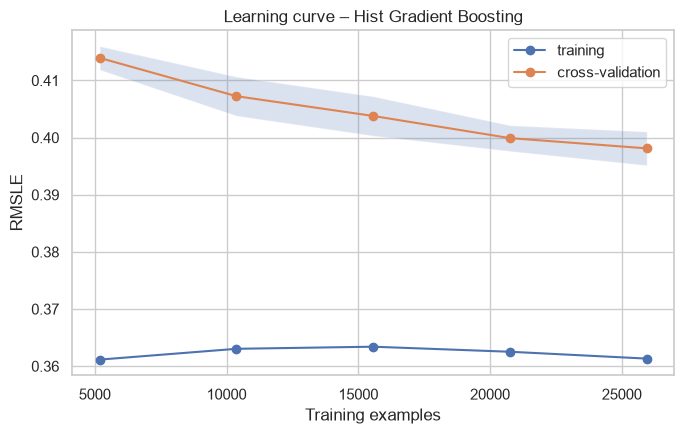

In [15]:
gap = train_m["r2_log"] - test_m["r2_log"]
print(f"R² (log price): train {train_m['r2_log']:.3f} vs test {test_m['r2_log']:.3f}  -> gap {gap:.3f}")
if gap > 0.10:
    print("DIAGNOSIS: possible OVER-fitting. Increase regularisation (min_samples_leaf, l2_regularization, alpha), "
          "reduce depth, or simplify features.")
elif test_m["r2_log"] < 0.5:
    print("DIAGNOSIS: possible UNDER-fitting. Add features or use a more flexible model.")
else:
    print("DIAGNOSIS: no serious over- or under-fitting; the model generalises.")

sizes, tr, va = learning_curve(clone(model), X_train, y_train, train_sizes=[.2, .4, .6, .8, 1.0], cv=3,
                               scoring=U.RMSLE_SCORER, n_jobs=-1, random_state=U.RANDOM_STATE, shuffle=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sizes, -tr.mean(1), "o-", label="training"); ax.plot(sizes, -va.mean(1), "o-", label="cross-validation")
ax.fill_between(sizes, -va.mean(1) - va.std(1), -va.mean(1) + va.std(1), alpha=.2)
ax.set(xlabel="Training examples", ylabel="RMSLE", title=f"Learning curve – {best_name}"); ax.legend()
savefig("08_learning_curve.png"); plt.show()

## 2.5 Error analysis and feature importance

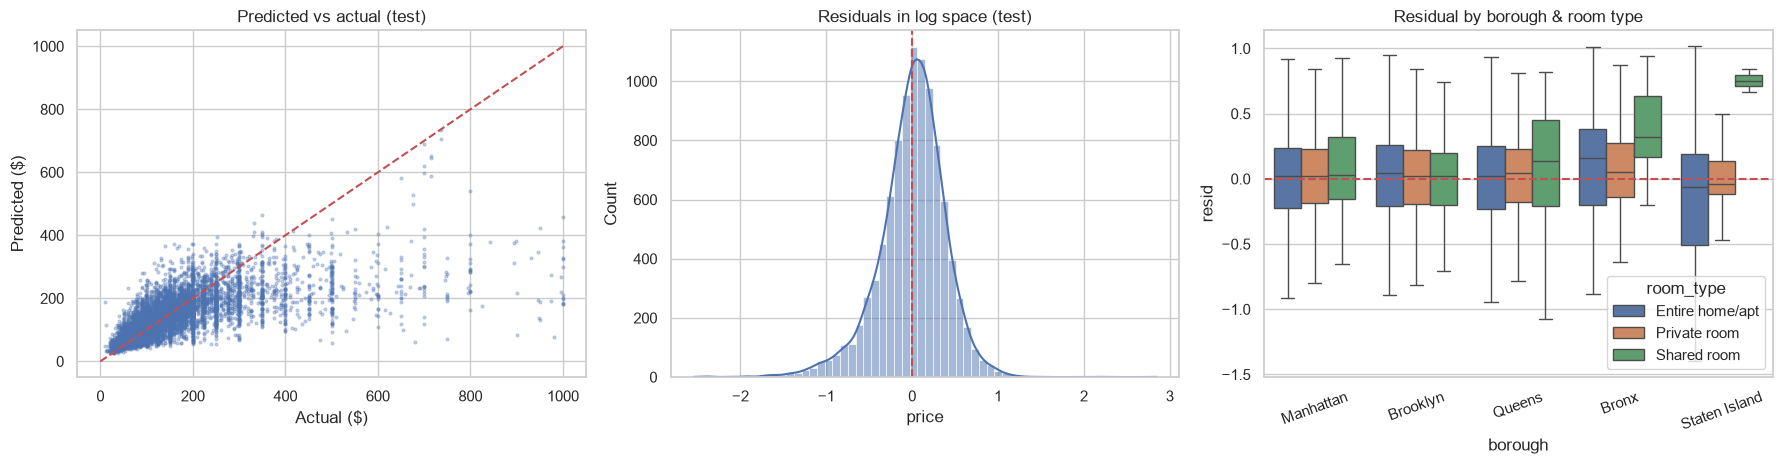

Error by actual-price quintile (mean bias > 0 = over-prediction, < 0 = under-prediction):


,n,MAE ($),median % error,mean bias ($)
bucket,,,,
"(9.999, 60.0]","2,037.000",16.541,26.694,15.194
"(60.0, 90.0]","2,009.000",21.296,19.375,10.165
"(90.0, 129.0]","1,825.000",30.288,22.013,12.468
"(129.0, 199.0]","1,936.000",35.891,18.131,2.471
"(199.0, 1000.0]","1,922.000",121.296,30.050,-110.148


In [16]:
resid = np.log1p(pred_test) - np.log1p(y_test)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(y_test, pred_test, s=4, alpha=.3); lim = [0, max(y_test.max(), pred_test.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="Actual ($)", ylabel="Predicted ($)", title="Predicted vs actual (test)")
sns.histplot(resid, bins=60, kde=True, ax=ax[1]); ax[1].axvline(0, c="r", ls="--"); ax[1].set(title="Residuals in log space (test)")
err = pd.DataFrame({"room_type": X_test["room_type"].values, "borough": X_test["neighbourhood_group"].values, "resid": resid.values})
sns.boxplot(data=err, x="borough", y="resid", hue="room_type", ax=ax[2], showfliers=False)
ax[2].axhline(0, c="r", ls="--"); ax[2].set(title="Residual by borough & room type"); ax[2].tick_params(axis="x", rotation=20)
savefig("09_error_analysis.png"); plt.show()

buckets = pd.qcut(y_test, 5, duplicates="drop")
by_price = pd.DataFrame({"actual": y_test.values, "pred": pred_test, "bucket": buckets.values}).groupby("bucket", observed=True).apply(
    lambda g: pd.Series({"n": len(g), "MAE ($)": (g.pred - g.actual).abs().mean(),
                         "median % error": ((g.pred - g.actual).abs() / g.actual).median() * 100,
                         "mean bias ($)": (g.pred - g.actual).mean()}))
print("Error by actual-price quintile (mean bias > 0 = over-prediction, < 0 = under-prediction):")
display(by_price)

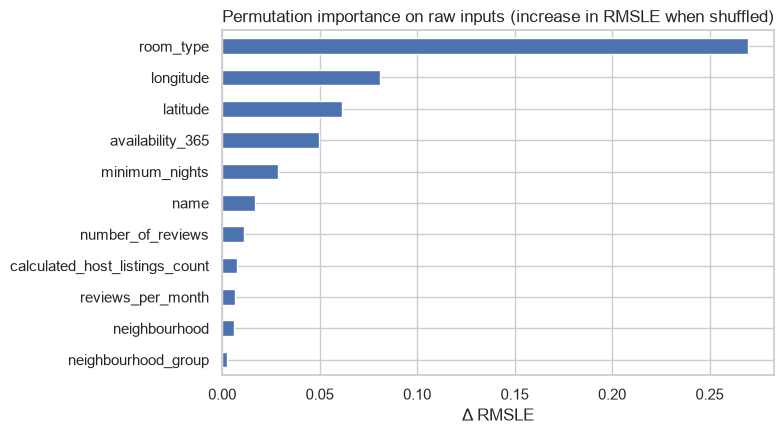

,importance
room_type,0.270
longitude,0.081
latitude,0.062
availability_365,0.049
minimum_nights,0.028
name,0.017
number_of_reviews,0.011
calculated_host_listings_count,0.008
reviews_per_month,0.007
neighbourhood,0.006


In [17]:
imp = U.raw_feature_importance(model, X_test, y_test)
fig, ax = plt.subplots(figsize=(8, 4.5))
imp[::-1].plot.barh(ax=ax); ax.set(title="Permutation importance on raw inputs (increase in RMSLE when shuffled)", xlabel="Δ RMSLE")
savefig("10_permutation_importance.png"); plt.show()
display(imp.to_frame("importance"))

## 2.6 Save the final pipeline for deployment
The saved object contains **everything**: feature engineering → encoding → scaling → tuned model → inverse log-transform. The app therefore only has to call `model.predict(raw_dataframe)`.
`models/metadata.json` stores the dropdown choices, per-neighbourhood coordinates/median prices and the evaluation metrics shown in the app.

In [18]:
model_path = MODELS_DIR / "airbnb_price_pipeline.joblib"
joblib.dump(model, model_path, compress=3)

meta = U.build_metadata(df, selected, best_name, best_params, train_m, test_m, comparison, info)
(MODELS_DIR / "metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
U.write_results_md(REPORTS_DIR / "results.md", meta)

size_mb = model_path.stat().st_size / 1e6
print(f"Saved {model_path} ({size_mb:.1f} MB), models/metadata.json, reports/results.md")
if size_mb > 90:
    print("WARNING: close to GitHub's 100 MB file limit – use a smaller model (see README).")

Saved models\airbnb_price_pipeline.joblib (0.5 MB), models/metadata.json, reports/results.md


## 2.7 Reload the pipeline and test it on realistic new listings
This is exactly what the web app does. The last column compares each estimate with the **median actual price of similar listings** (same borough and room type) as a sanity check.

In [19]:
loaded = joblib.load(model_path)
scenarios = {
    "Manhattan – modern entire apt, Midtown": dict(neighbourhood_group="Manhattan", neighbourhood="Midtown", room_type="Entire home/apt",
        latitude=40.7549, longitude=-73.9840, minimum_nights=3, number_of_reviews=45, reviews_per_month=1.2,
        calculated_host_listings_count=1, availability_365=200, name="Modern spacious 1BR near Times Square"),
    "Brooklyn – private room, Williamsburg": dict(neighbourhood_group="Brooklyn", neighbourhood="Williamsburg", room_type="Private room",
        latitude=40.7144, longitude=-73.9610, minimum_nights=2, number_of_reviews=20, reviews_per_month=0.8,
        calculated_host_listings_count=1, availability_365=120, name="Cozy private room"),
    "Queens – shared room, Astoria": dict(neighbourhood_group="Queens", neighbourhood="Astoria", room_type="Shared room",
        latitude=40.7644, longitude=-73.9235, minimum_nights=1, number_of_reviews=5, reviews_per_month=0.3,
        calculated_host_listings_count=3, availability_365=300, name="Budget bunk bed near subway"),
    "Bronx – entire apt, new listing (0 reviews)": dict(neighbourhood_group="Bronx", neighbourhood=df.loc[df.neighbourhood_group == "Bronx", "neighbourhood"].mode().iloc[0],
        room_type="Entire home/apt", latitude=40.85, longitude=-73.88, minimum_nights=30, number_of_reviews=0, reviews_per_month=0.0,
        calculated_host_listings_count=1, availability_365=365, name="Renovated 2 bedroom"),
}
rows = []
for label, s in scenarios.items():
    comp = df[(df.neighbourhood_group == s["neighbourhood_group"]) & (df.room_type == s["room_type"])]["price"].median()
    rows.append({"scenario": label, "estimated $/night": U.predict_price(loaded, s), "median of similar listings $": comp})
display(pd.DataFrame(rows))

# robustness: unseen neighbourhood + missing title must not crash
print("Unseen neighbourhood ->", round(U.predict_price(loaded, {"neighbourhood": "Atlantis", "name": ""}), 1))

,scenario,estimated $/night,median of similar listings $
0,"Manhattan – modern entire apt, Midtown",282.514,190.000
1,"Brooklyn – private room, Williamsburg",80.326,65.000
2,"Queens – shared room, Astoria",52.815,37.000
3,"Bronx – entire apt, new listing (0 reviews)",132.023,100.000


Unseen neighbourhood -> 264.0


---
# Task 3 – Streamlit Application
The app (`app.py`) loads `models/airbnb_price_pipeline.joblib` + `models/metadata.json` and provides:

* inputs for borough, neighbourhood (coordinates auto-fill), room type, title, minimum nights, availability, reviews, host listings;
* three one-click realistic examples;
* the estimated nightly price with a ±1-error range and the neighbourhood's median price for context;
* input validation warnings (e.g. coordinates outside NYC), a map, a *Model performance* tab and an *About & limitations* tab.

**Run it** from the repository root:

```bash
streamlit run app.py
```

Deployment instructions (Streamlit Community Cloud) and screenshots are in `README.md`.

---
# Task 4 – Final Project Summary

In [20]:
c = meta["cleaning"]
print("FINAL PROJECT SUMMARY (generated from this run)")
print("=" * 70)
print(f"Data        : {c['rows_raw']:,} raw listings -> {c['rows_clean']:,} after cleaning "
      f"(price kept in ${c['min_price']:.0f}-${c['price_cap']:.0f}; {c['price_zero_or_below']} zero/negative prices removed)")
print(f"Features    : {len(U.CAT_FEATURES)} categorical + {len(selected)} numeric engineered features")
print("Model comparison (CV RMSLE, lower is better):")
for _, r in comparison.iterrows():
    print(f"   {r['model']:<24} {r['cv_rmsle']:.3f}   (CV R² {r['cv_r2']:.3f}, train-CV gap {r['overfit_gap_rmsle']:+.3f})")
print(f"Final model : {best_name}, tuned with randomised search ({N_ITER} iterations, {CV}-fold CV)")
print(f"Test set    : R² = {test_m['r2']:.3f} | MAE = ${test_m['mae']:.2f} | RMSE = ${test_m['rmse']:.2f} | "
      f"RMSLE = {test_m['rmsle']:.3f} | median abs. error = {test_m['median_ape_pct']:.1f}%")
print(f"Generalisation: train R²(log) {train_m['r2_log']:.3f} vs test {test_m['r2_log']:.3f} (gap {gap:.3f})")
print(f"Top drivers : " + ", ".join(imp.head(4).index))
print("Deliverables: models/airbnb_price_pipeline.joblib, models/metadata.json, app.py, reports/results.md, images/*.png")

FINAL PROJECT SUMMARY (generated from this run)
Data        : 48,895 raw listings -> 48,645 after cleaning (price kept in $10-$1000; 11 zero/negative prices removed)
Features    : 3 categorical + 17 numeric engineered features
Model comparison (CV RMSLE, lower is better):
   Hist Gradient Boosting   0.399   (CV R² 0.439, train-CV gap +0.040)
   Random Forest            0.401   (CV R² 0.424, train-CV gap +0.072)
   Ridge                    0.422   (CV R² 0.369, train-CV gap +0.002)
   Linear Regression        0.422   (CV R² 0.369, train-CV gap +0.002)
Final model : Hist Gradient Boosting, tuned with randomised search (20 iterations, 3-fold CV)
Test set    : R² = 0.465 | MAE = $44.65 | RMSE = $86.42 | RMSLE = 0.389 | median abs. error = 22.5%
Generalisation: train R²(log) 0.693 vs test 0.661 (gap 0.032)
Top drivers : room_type, longitude, latitude, availability_365
Deliverables: models/airbnb_price_pipeline.joblib, models/metadata.json, app.py, reports/results.md, images/*.png


## Limitations and future work

1. **Stale data (2019).** Prices, regulations and demand have changed (COVID-19, NYC short-term-rental rules). The model must be retrained on current data before real use.
2. **Missing key price drivers.** The dataset has no bedrooms/bathrooms, capacity, amenities, photos, star ratings, host quality or seasonality, so two very different flats at the same address get similar estimates. This caps achievable accuracy.
3. **Asking price ≠ paid price.** Targets are listed prices, not realised bookings.
4. **Outlier trimming.** Listings below $10 or above the 99.5th percentile were removed, so the most expensive listings tend to be **under-estimated** (check the mean-bias column of the error-by-price table: models regress towards the mean).
5. **Geographic coverage.** Only NYC; coordinates outside the five boroughs are warned about but not supported. Neighbourhoods with very few listings are grouped as "infrequent".
6. **Weak title signal.** Title keywords are simple regex flags; real NLP (embeddings) might add a little but risks over-fitting.
7. **Uncertainty.** The app shows a ±1-RMSLE band, which is a population-level approximation, not a per-listing prediction interval (quantile regression or conformal prediction would be better).
8. **Fairness/ethics.** Price estimates tied to neighbourhood can reinforce existing market inequalities; they should support, not replace, a host's judgement.

**Future work:** retrain on recent InsideAirbnb snapshots, add amenities/bedroom features, gradient-boosted quantile models for intervals, SHAP explanations in the app, scheduled re-training.